# **Activity 3 — Object Counting**

**Ronald William D. Geron** · **CPE4A** · **Computer Engineering**

---

### **Pipeline Overview**
**Input:** `coins.png`  
**Sequence:** `RGB Channel Thresholding` $\rightarrow$ `Channel Intersection` $\rightarrow$ `Mask Inversion` $\rightarrow$ `Hole Filling (Flood Fill)` $\rightarrow$ `Morphological Opening` $\rightarrow$ `Connected Components` $\rightarrow$ `Area Classification` $\rightarrow$ `Bounding Box Visualization`

> **Project Description:**  
> This implementation processes an image containing various Philippine coin denominations including old bi-metallic **10 Peso**, old gold **5 Peso**, **20 Peso**, **1 Peso**, and **25 Cents**. It isolates individual coins using morphological segmentation and accurately classifies each coin based on calibrated pixel surface area thresholds.

---

## **Part 1: Import Libraries & Load Image**
* **Goal:** Initialize required modules and load input dataset.
* **Process:** Imports computer vision and data visualization libraries (`opencv`, `numpy`, `matplotlib`, `scikit-image`). Reads `coins.png` from disk, verifies image presence, and converts default BGR color channel ordering to RGB for correct display visualization.

---

In [ ]:
!pip install opencv-python scikit-image matplotlib numpy

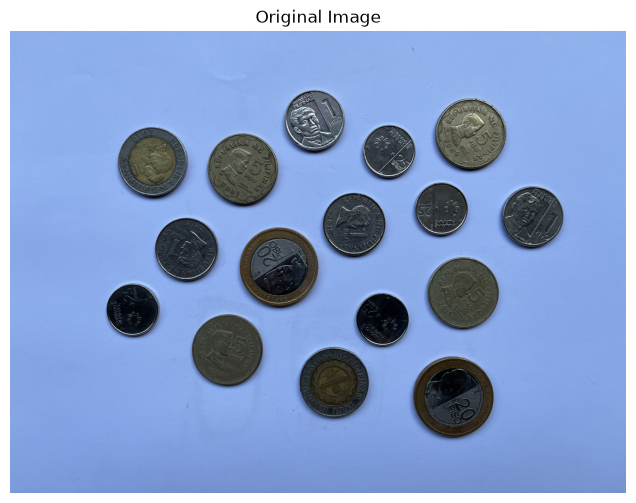

In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.morphology import disk, opening

# Load image
image = cv2.imread('coins.png')
if image is None:
    raise FileNotFoundError("Image not found. Siguraduhing tama ang filename.")

# Convert BGR to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display loaded image
plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

## **Part 2: RGB Thresholding & Channel Masking**
* **Goal:** Separate coin foreground boundaries from the white background.
* **Process:** Splits the RGB channels (`Red`, `Green`, `Blue`) and applies threshold levels (`R > 51`, `G > 102`, `B > 114`). Merges the binary channels using `cv2.bitwise_and` to capture white background pixels, then inverts the mask (`cv2.bitwise_not`) to isolate the coins as bright foreground objects.

---

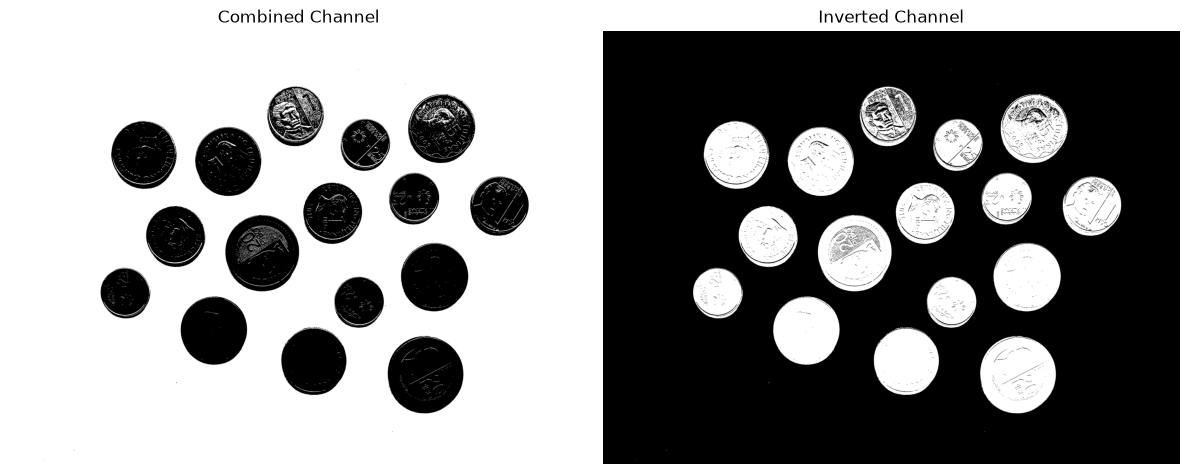

In [28]:
# Separate RGB Channels
rmat = image_rgb[:, :, 0]
gmat = image_rgb[:, :, 1]
bmat = image_rgb[:, :, 2]

# Threshold levels (scaled 0-255)
Ired = (rmat > (0.2 * 255)).astype(np.uint8)
Igreen = (gmat > (0.4 * 255)).astype(np.uint8)
Iblue = (bmat > (0.45 * 255)).astype(np.uint8)

# Combine channels using bitwise AND
It = cv2.bitwise_and(cv2.bitwise_and(Ired, Igreen), Iblue)

# Invert mask
Icomp = cv2.bitwise_not(It * 255)

# Display intermediate channels
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].imshow(It, cmap='gray')
axs[0].set_title("Combined Channel")
axs[0].axis("off")

axs[1].imshow(Icomp, cmap='gray')
axs[1].set_title("Inverted Channel")
axs[1].axis("off")

plt.tight_layout()
plt.show()

## **Part 3: Hole Filling & Morphological Operations**
* **Goal:** Clean binary masks and isolate touching coin contours.
* **Process:** Applies OpenCV's `floodFill` algorithm to fill internal coin surface highlights and hole gaps. Performs morphological `opening` using a disk-shaped structuring element (radius = 15) to remove outer pixel noise and separate coin edges. Converts binary shapes into labeled connected components using `skimage.measure.label`.

---

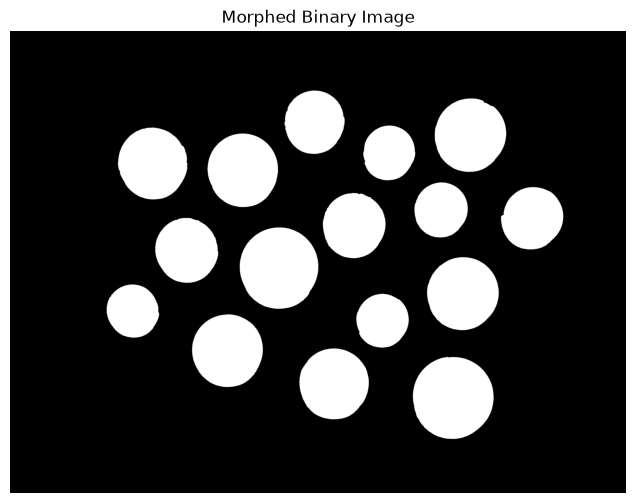

In [29]:
# Flood fill to fill internal holes
flood_fill = Icomp.copy()
h, w = flood_fill.shape
mask = np.zeros((h + 2, w + 2), np.uint8)
cv2.floodFill(flood_fill, mask, (0, 0), 255)

filled = cv2.bitwise_or(Icomp, cv2.bitwise_not(flood_fill))

# Morphological opening using disk structuring element
opened = opening(filled // 255, disk(15)).astype(np.uint8)

# Label connected components
label_image = label(opened)
regions = regionprops(label_image)

# Display morphed binary image
plt.figure(figsize=(8, 6))
plt.imshow(opened, cmap='gray')
plt.title("Morphed Binary Image")
plt.axis("off")
plt.show()

## **Part 4: Region Area Inspection**
* **Goal:** Measure pixel area dimensions of every segmented region.
* **Process:** Loops through `regionprops` components and prints the calculated pixel area for each coin. Serves as an analytical diagnostic step to determine exact cutoff boundary points between distinct physical coin sizes.

---

In [30]:
# Print area sizes para makita ang eksaktong pixel counts ng bawat barya
print("--- List ng Pixel Areas ng Bawat Barya ---")
for i, region in enumerate(regions):
    print(f"Coin {i+1} Area: {region.area}")

--- List ng Pixel Areas ng Bawat Barya ---
Coin 1 Area: 127311.0
Coin 2 Area: 175691.0
Coin 3 Area: 95369.0
Coin 4 Area: 166283.0
Coin 5 Area: 174323.0
Coin 6 Area: 98428.0
Coin 7 Area: 128736.0
Coin 8 Area: 136884.0
Coin 9 Area: 135900.0
Coin 10 Area: 215384.0
Coin 11 Area: 175116.0
Coin 12 Area: 92676.0
Coin 13 Area: 94372.0
Coin 14 Area: 173011.0
Coin 15 Area: 165583.0
Coin 16 Area: 223661.0


## **Part 5: Area-Based Coin Classification**
* **Goal:** Classify detected objects into specific Philippine coin denominations.
* **Process:** Categorizes segmented region objects into **25 Cents**, **1 Peso**, **10 Peso**, **5 Peso**, and **20 Peso**.

> **Key Technical Note on Threshold Calibration:**  
> The **Old 5 Peso coin (27 mm)** is physically larger than the **Old 10 Peso coin (26.5 mm)**. The cutoff ranges are calibrated (`140,000–170,000` pixels for **10 Peso** vs `170,000–195,000` pixels for **5 Peso**) to prevent detection reversal errors between these two denominations.

---

In [31]:
# Inayos na area thresholds:
# Old 10 Peso (26.5mm) = mas maliit sa Old 5 Peso (27mm)
cents, one, ten, five, bente = [], [], [], [], []

for region in regions:
    area = region.area
    
    if area < 100000:
        cents.append(region)
    elif area < 140000:
        one.append(region)
    elif area < 170000:
        ten.append(region)     # 10 Peso (mas maliit na area)
    elif area < 195000:
        five.append(region)    # 5 Peso (mas malaking area)
    else:
        bente.append(region)   # 20 Peso (pinakamalaki)

## **Part 6: Bounding Box Visualization & Final Summary**
* **Goal:** Overlay detection boxes and display final coin counts.
* **Process:** Draws color-coded bounding rectangles (`cv2.rectangle`) and text labels (`cv2.putText`) over each classified coin based on its bounding box coordinates. Displays the annotated image output and prints an itemized summary count per denomination along with total coin quantity.

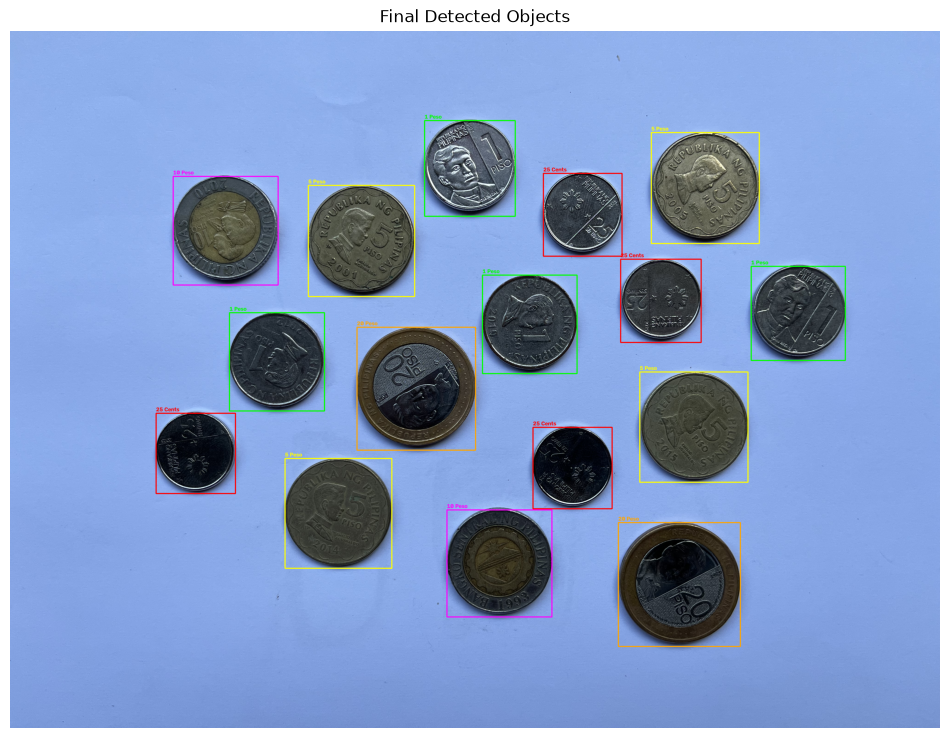

=== FINAL COUNT ===
25 Cents : 4
1 Peso   : 4
5 Peso   : 4
10 Peso  : 2
20 Peso  : 2
Total    : 16


In [32]:
output_img = image_rgb.copy()

# Function para mag-draw ng bounding boxes
def draw_boxes(region_list, label_text, color):
    for region in region_list:
        minr, minc, maxr, maxc = region.bbox
        cv2.rectangle(output_img, (minc, minr), (maxc, maxr), color, 3)
        cv2.putText(output_img, label_text, (minc, minr - 8), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

# Draw boxes per denomination
draw_boxes(cents, "25 Cents", (255, 0, 0))     # Blue
draw_boxes(one, "1 Peso", (0, 255, 0))         # Green
draw_boxes(ten, "10 Peso", (255, 0, 255))      # Magenta
draw_boxes(five, "5 Peso", (255, 255, 0))      # Cyan/Yellow
draw_boxes(bente, "20 Peso", (255, 165, 0))    # Orange

# Display Final Output
plt.figure(figsize=(12, 10))
plt.imshow(output_img)
plt.title("Final Detected Objects")
plt.axis("off")
plt.show()

# Print Totals
print("=== FINAL COUNT ===")
print(f"25 Cents : {len(cents)}")
print(f"1 Peso   : {len(one)}")
print(f"5 Peso   : {len(five)}")
print(f"10 Peso  : {len(ten)}")
print(f"20 Peso  : {len(bente)}")
print(f"Total    : {len(regions)}")